DATASET CREATED SUCCESSFULLY!
    Size  Bedrooms  Bathrooms  Age     Price
0    500         1          1   20   2000000
1    600         1          1   18   2500000
2    700         2          1   15   3000000
3    800         2          2   12   3500000
4    900         2          2   10   4000000
5   1000         2          2    8   4500000
6   1100         3          2    7   5000000
7   1200         3          2    6   5500000
8   1300         3          2    5   6000000
9   1400         3          3    4   6500000
10  1500         3          3    3   7000000
11  1600         3          3    5   7200000
12  1700         4          3    4   7800000
13  1800         4          3    3   8200000
14  1900         4          3    2   8800000
15  2000         4          3    2   9200000
16  2100         4          4    1   9800000
17  2200         5          4    3  10500000
18  2300         5          4    1  11000000
19  2400         5          4    0  11500000

FIRST FIVE ROWS
   Size 

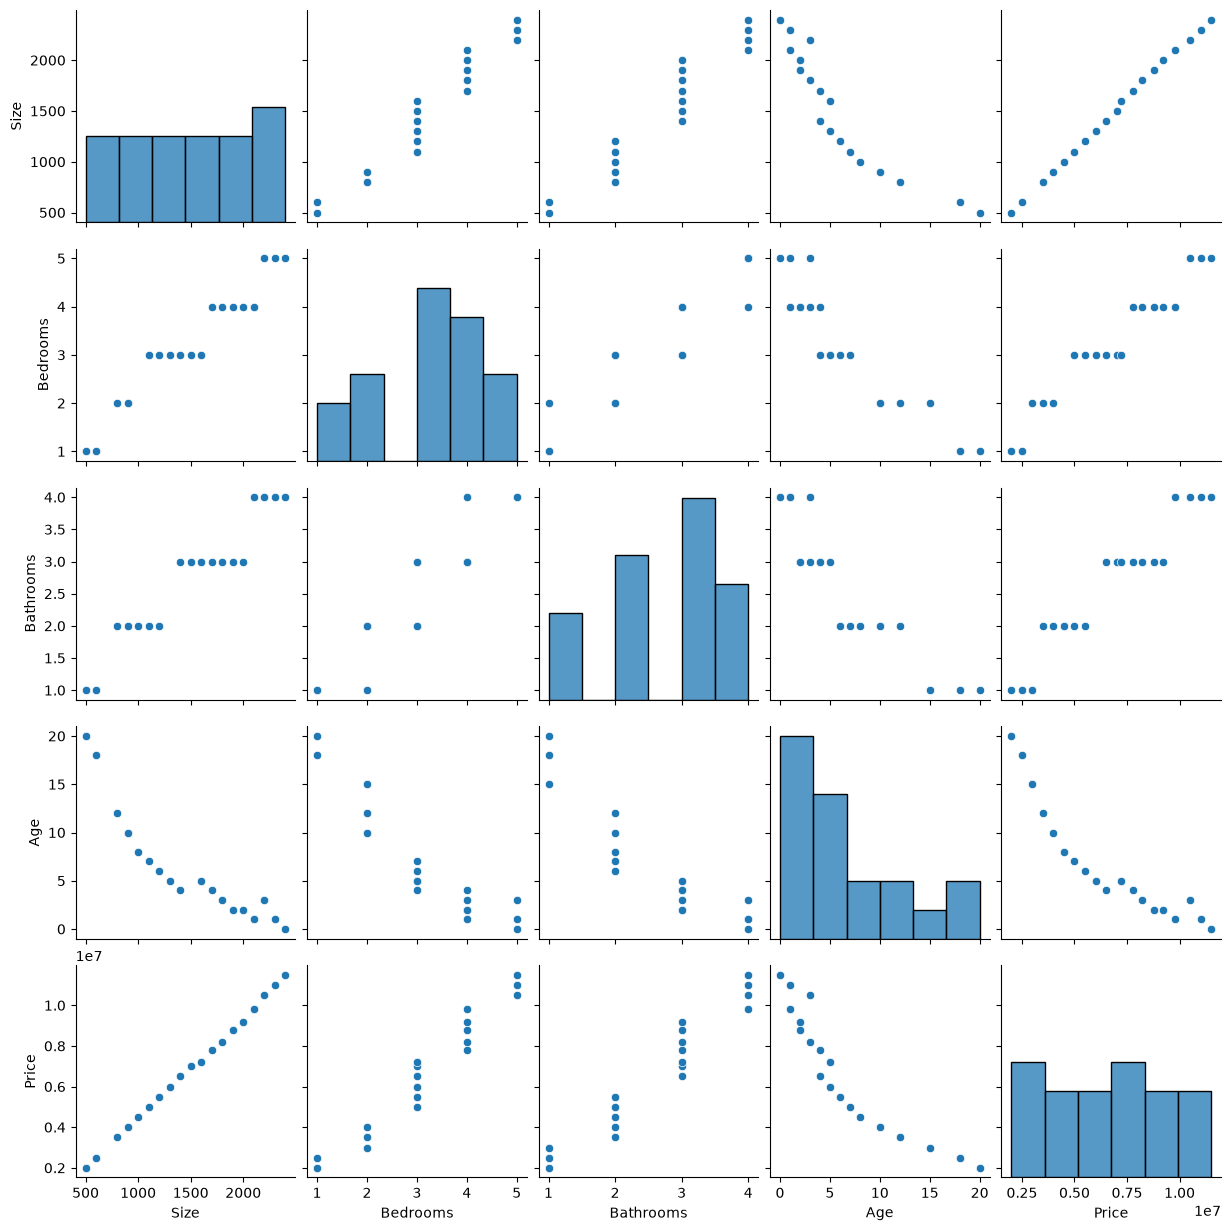

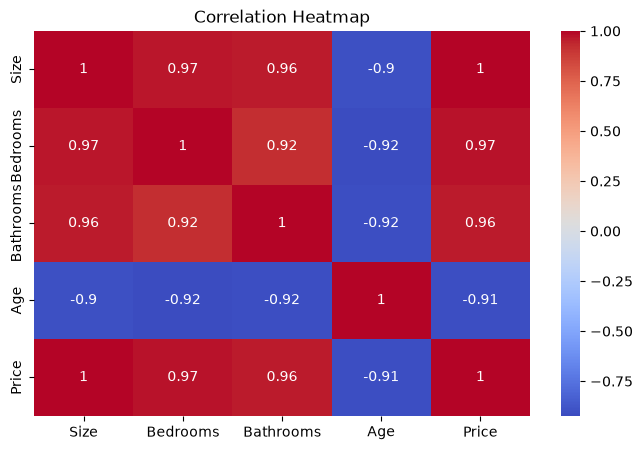


INPUT FEATURES
     Size  Bedrooms  Bathrooms   Age
0   500.0       1.0        1.0  20.0
1   600.0       1.0        1.0  18.0
2  1500.0       2.0        1.0  15.0
3   800.0       2.0        2.0  12.0
4   900.0       2.0        2.0  10.0

OUTPUT VARIABLE
0    2000000
1    2500000
2    3000000
3    3500000
4    4000000
Name: Price, dtype: int64

TRAINING DATA SHAPE: (16, 4)
TESTING DATA SHAPE: (4, 4)

MODEL TRAINED SUCCESSFULLY!

MODEL INTERCEPT:
46577.81674373988

MODEL COEFFICIENTS:
Size : 1765.3228828265787
Bedrooms : 666993.1388991011
Bathrooms : 909095.0513491153
Age : -114164.48088823244

PREDICTED HOUSE PRICES
[  222037.8306406  10559140.61618948  8744152.33026418   626899.08069972]

ACTUAL VS PREDICTED PRICES
   Actual Price  Predicted Price
0       2000000     2.220378e+05
1      10500000     1.055914e+07
2       9200000     8.744152e+06
3       2500000     6.268991e+05

MODEL EVALUATION RESULTS
MAE: 1041512.8436462458
MSE: 1720237810010.9004
RMSE: 1311578.3659434537
R2 SCORE: 

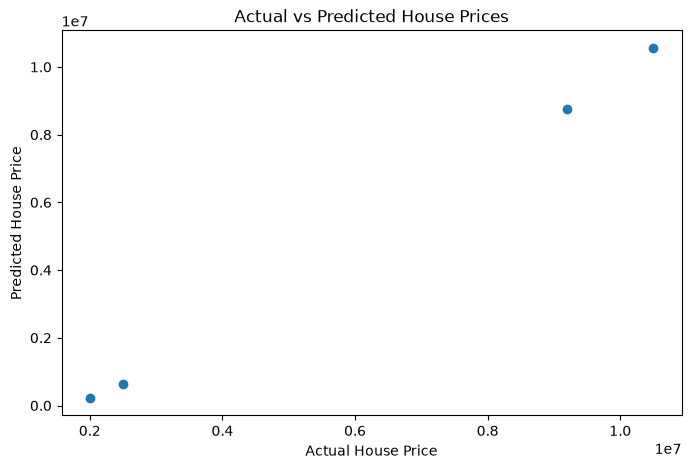

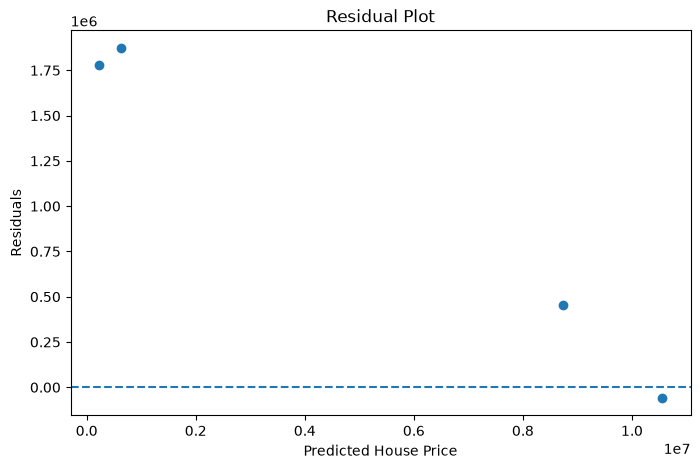


NEW HOUSE DETAILS
   Size  Bedrooms  Bathrooms  Age
0  1500         3          2    5

PREDICTED HOUSE PRICE:
Rs. 5942909.26

HOUSE PRICE PREDICTION COMPLETED!


In [1]:

# ============================================================
# PROJECT: HOUSE PRICE PREDICTION USING MULTIPLE LINEAR REGRESSION
# ============================================================


# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# STEP 2: CREATE DATASET

data = {
    "Size": [
        500, 600, 700, 800, 900, 1000, 1100, 1200,
        1300, 1400, 1500, 1600, 1700, 1800, 1900,
        2000, 2100, 2200, 2300, 2400
    ],

    "Bedrooms": [
        1, 1, 2, 2, 2, 2, 3, 3, 3, 3,
        3, 3, 4, 4, 4, 4, 4, 5, 5, 5
    ],

    "Bathrooms": [
        1, 1, 1, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 3, 3, 4, 4, 4, 4
    ],

    "Age": [
        20, 18, 15, 12, 10, 8, 7, 6, 5, 4,
        3, 5, 4, 3, 2, 2, 1, 3, 1, 0
    ],

    "Price": [
        2000000, 2500000, 3000000, 3500000,
        4000000, 4500000, 5000000, 5500000,
        6000000, 6500000, 7000000, 7200000,
        7800000, 8200000, 8800000, 9200000,
        9800000, 10500000, 11000000, 11500000
    ]
}

df = pd.DataFrame(data)

print("DATASET CREATED SUCCESSFULLY!")

print(df)


# STEP 3: EXPLORE DATASET

print("\nFIRST FIVE ROWS")
print(df.head())

print("\nDATASET SHAPE")
print(df.shape)

print("\nDATASET INFORMATION")
df.info()

print("\nSTATISTICAL SUMMARY")
print(df.describe())


# STEP 4: CHECK MISSING VALUES

print("\nMISSING VALUES")
print(df.isnull().sum())


# STEP 5: HANDLE MISSING VALUES

# Add a few missing values for demonstration

df.loc[2, "Size"] = np.nan
df.loc[5, "Bedrooms"] = np.nan
df.loc[8, "Bathrooms"] = np.nan
df.loc[10, "Age"] = np.nan

print("\nMISSING VALUES AFTER ADDING")
print(df.isnull().sum())

# Separate input features and target

X = df[["Size", "Bedrooms", "Bathrooms", "Age"]]
y = df["Price"]

# Fill missing input values using median

imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print("\nMISSING VALUES AFTER CLEANING")
print(X.isnull().sum())


# STEP 6: DATA VISUALIZATION

# Pairplot

sns.pairplot(df)
plt.show()

# Correlation heatmap

plt.figure(figsize=(8, 5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()


# STEP 7: SEPARATE INDEPENDENT AND DEPENDENT VARIABLES

X = df[["Size", "Bedrooms", "Bathrooms", "Age"]]

# Fill missing values again for the feature matrix
X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

y = df["Price"]

print("\nINPUT FEATURES")
print(X.head())

print("\nOUTPUT VARIABLE")
print(y.head())


# STEP 8: SPLIT TRAINING AND TESTING DATA

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTRAINING DATA SHAPE:", X_train.shape)
print("TESTING DATA SHAPE:", X_test.shape)


# STEP 9: CREATE MULTIPLE LINEAR REGRESSION MODEL

model = LinearRegression()


# STEP 10: TRAIN THE MODEL

model.fit(X_train, y_train)

print("\nMODEL TRAINED SUCCESSFULLY!")


# STEP 11: DISPLAY COEFFICIENTS AND INTERCEPT

print("\nMODEL INTERCEPT:")
print(model.intercept_)

print("\nMODEL COEFFICIENTS:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)


# STEP 12: PREDICT HOUSE PRICES

y_pred = model.predict(X_test)

print("\nPREDICTED HOUSE PRICES")
print(y_pred)


# STEP 13: COMPARE ACTUAL AND PREDICTED VALUES

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("\nACTUAL VS PREDICTED PRICES")
print(comparison)


# STEP 14: MODEL EVALUATION

# Mean Absolute Error

mae = mean_absolute_error(y_test, y_pred)

# Mean Squared Error

mse = mean_squared_error(y_test, y_pred)

# Root Mean Squared Error

rmse = np.sqrt(mse)

# R2 Score

r2 = r2_score(y_test, y_pred)


print("\nMODEL EVALUATION RESULTS")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 SCORE:", r2)


# STEP 15: ACTUAL VS PREDICTED GRAPH

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")

plt.title("Actual vs Predicted House Prices")

plt.show()


# STEP 16: RESIDUAL PLOT

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Price")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()


# STEP 17: PREDICT PRICE OF A NEW HOUSE

new_house = pd.DataFrame({
    "Size": [1500],
    "Bedrooms": [3],
    "Bathrooms": [2],
    "Age": [5]
})

prediction = model.predict(new_house)

print("\nNEW HOUSE DETAILS")
print(new_house)

print("\nPREDICTED HOUSE PRICE:")
print("Rs.", round(prediction[0], 2))


# STEP 18: PROJECT COMPLETION

print("\n===================================")
print("HOUSE PRICE PREDICTION COMPLETED!")
print("===================================")


In [ ]:
1. Import Libraries

2. Create Dataset

3. Explore Data

4. Handle Missing Values

5. Data Visualization

6. Separate X and y

7. Train-Test Split

8. Create Model

9. Train Model

10. Make Predictions

11. Evaluate Model

12. Predict New House